In [14]:
import pandas as pd
import numpy as np

In [15]:
df=pd.read_csv(r"D:\My_Projects\Fifth_Project\Cryptocast\Data\Processed\cleaned_bitcoin.csv")

In [16]:
df['date']=pd.to_datetime(df['date'])
df=df.sort_values('date').reset_index(drop=True)


In [17]:
df.sample(5)

,date,price,open,high,low,vol,change_pct
739,2012-07-26,8.9,8.8,8.9,8.6,32380.0,1.14
1484,2014-08-10,592.1,589.5,596.6,588.1,1340.0,0.43
3390,2019-10-29,9411.3,9206.5,9531.3,9125.3,918480.0,2.22
218,2011-02-21,0.8,0.9,0.9,0.8,1700.0,0.00
2221,2016-08-16,580.2,567.0,583.4,563.4,37690.0,2.34


In [18]:
data=df[['price']].values

train_size=int(len(data)*0.80)
train_data=data[:train_size]
test_data=data[train_size:]

print(f"Total record: {len(data)}")
print(f"Training Records (80%) : {len(train_data)}")
print(f"Test Records (20%) : {len(test_data)}")


Total record: 4999
Training Records (80%) : 3999
Test Records (20%) : 1000


In [19]:
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler(feature_range=(0,1))
scaled_train=scaler.fit_transform(train_data)
scaled_test=scaler.transform(test_data)


In [28]:
def multi_horizon_seq(data,lookback=60):
    X,y_1d,y_3d,y_7d=[],[],[],[]
    for i in range(lookback,len(data)-7):
        X.append(data[i-lookback:i,0])
        y_1d.append(data[i,0])
        y_3d.append(data[i:i+3,0])
        y_7d.append(data[i:i+7,0])

    X=np.array(X)
    y_1d=np.array(y_1d)
    y_3d=np.array(y_3d)
    y_7d=np.array(y_7d)

    X=np.reshape(X,(X.shape[0],X.shape[1],1))
    return X, y_1d,y_3d,y_7d

In [21]:
X_train, y_train_1d, y_train_3d, y_train_7d = multi_horizon_seq(scaled_train, lookback=60)

X_test, y_test_1d, y_test_3d, y_test_7d = multi_horizon_seq(scaled_test, lookback=60)

print(f"X_train Shape: {X_train.shape}")
print(f"y_train 1D Shape: {y_train_1d.shape}")
print(f"y_train 3D Shape: {y_train_3d.shape}")
print(f"y_train 7D Shape: {y_train_7d.shape}")
print("---")
print(f"X_test Shape: {X_test.shape}")
print(f"y_test 1D Shape: {y_test_1d.shape}")
print(f"y_test 3D Shape: {y_test_3d.shape}")
print(f"y_test 7D Shape: {y_test_7d.shape}")

X_train Shape: (3932, 60, 1)
y_train 1D Shape: (3932,)
y_train 3D Shape: (3932, 3)
y_train 7D Shape: (3932, 7)
---
X_test Shape: (933, 60, 1)
y_test 1D Shape: (933,)
y_test 3D Shape: (933, 3)
y_test 7D Shape: (933, 7)


,Model,Horizon,RMSE ($),MAE ($),MAPE (%)
0,1D-CNN,1-Day,2543.52,1874.29,5.35
1,Simple RNN,1-Day,1196.94,785.30,2.29
2,Stacked LSTM,1-Day,2200.39,1442.11,3.80
3,Transformer,1-Day,30658.76,27808.71,79.87
4,1D-CNN,3-Day,2986.02,2318.70,7.24
5,Simple RNN,3-Day,1764.47,1188.71,3.48
6,Stacked LSTM,3-Day,4046.56,3118.32,8.49
7,Transformer,3-Day,31338.70,28541.28,82.30
8,1D-CNN,7-Day,4814.21,3782.46,10.79
9,Simple RNN,7-Day,2473.08,1767.56,5.32


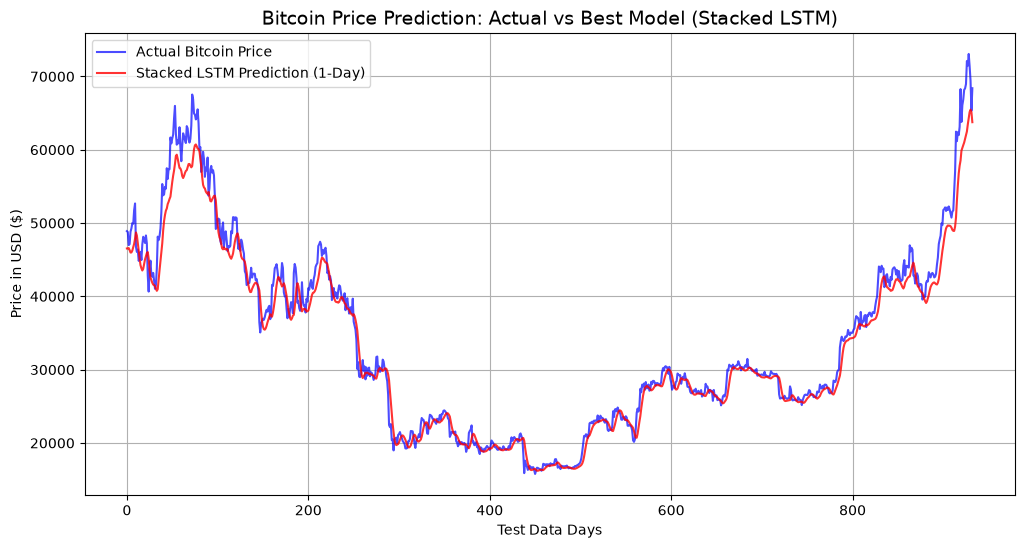

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, Conv1D, MaxPooling1D, Flatten, SimpleRNN, LSTM, MultiHeadAttention, LayerNormalization, GlobalAveragePooling1D

def evaluate_model(model, X_tr, y_tr, X_te, y_te, horizon_name):
   
    model.compile(optimizer='adam', loss='mean_squared_error')
    model.fit(X_tr, y_tr, epochs=15, batch_size=32, verbose=0)
    

    pred_scaled = model.predict(X_te, verbose=0)
    pred_actual = scaler.inverse_transform(pred_scaled)
    test_actual = scaler.inverse_transform(y_te.reshape(-1, 1) if y_te.ndim == 1 else y_te)
   
    rmse = np.sqrt(mean_squared_error(test_actual, pred_actual))
    mae = mean_absolute_error(test_actual, pred_actual)
    mape = np.mean(np.abs((test_actual - pred_actual) / test_actual)) * 100
    
    return round(rmse, 2), round(mae, 2), round(mape, 2), pred_actual

def get_model(model_type, out_dim):
    if model_type == '1D-CNN':
        return Sequential([
            Input(shape=(60, 1)),
            Conv1D(64, kernel_size=3, activation='relu'),
            MaxPooling1D(pool_size=2),
            Flatten(),
            Dense(50, activation='relu'),
            Dropout(0.2),
            Dense(out_dim)
        ])
    elif model_type == 'Simple RNN':
        return Sequential([
            Input(shape=(60, 1)),
            SimpleRNN(50, activation='tanh'),
            Dropout(0.2),
            Dense(25, activation='relu'),
            Dense(out_dim)
        ])
    elif model_type == 'Stacked LSTM':
        return Sequential([
            Input(shape=(60, 1)),
            LSTM(50, return_sequences=True),
            Dropout(0.2),
            LSTM(50),
            Dropout(0.2),
            Dense(25, activation='relu'),
            Dense(out_dim)
        ])
    elif model_type == 'Transformer':
        inp = Input(shape=(60, 1))
        att = MultiHeadAttention(num_heads=2, key_dim=16)(inp, inp)
        x = LayerNormalization()(inp + att)
        ff = Dense(32, activation='relu')(x)
        x = LayerNormalization()(x + ff)
        x = GlobalAveragePooling1D()(x)
        out = Dense(out_dim)(x)
        return Model(inputs=inp, outputs=out)

horizons = [('1-Day', y_train_1d, y_test_1d, 1), 
            ('3-Day', y_train_3d, y_test_3d, 3), 
            ('7-Day', y_train_7d, y_test_7d, 7)]

models = ['1D-CNN', 'Simple RNN', 'Stacked LSTM', 'Transformer']
results = []
best_lstm_preds = None



for h_name, y_tr, y_te, out_dim in horizons:
    for m_name in models:
        model = get_model(m_name, out_dim)
        rmse, mae, mape, preds = evaluate_model(model, X_train, y_tr, X_test, y_te, h_name)
        results.append({'Model': m_name, 'Horizon': h_name, 'RMSE ($)': rmse, 'MAE ($)': mae, 'MAPE (%)': mape})
 
        if m_name == 'Stacked LSTM' and h_name == '1-Day':
            best_lstm_preds = preds

results_df = pd.DataFrame(results)
display(results_df)

actual_1d = scaler.inverse_transform(y_test_1d.reshape(-1, 1))

plt.figure(figsize=(12, 6))
plt.plot(actual_1d, label='Actual Bitcoin Price', color='blue', alpha=0.7)
plt.plot(best_lstm_preds, label='Stacked LSTM Prediction (1-Day)', color='red', alpha=0.8)
plt.title('Bitcoin Price Prediction: Actual vs Best Model (Stacked LSTM)', fontsize=14)
plt.xlabel('Test Data Days')
plt.ylabel('Price in USD ($)')
plt.legend()
plt.grid(True)
plt.show()

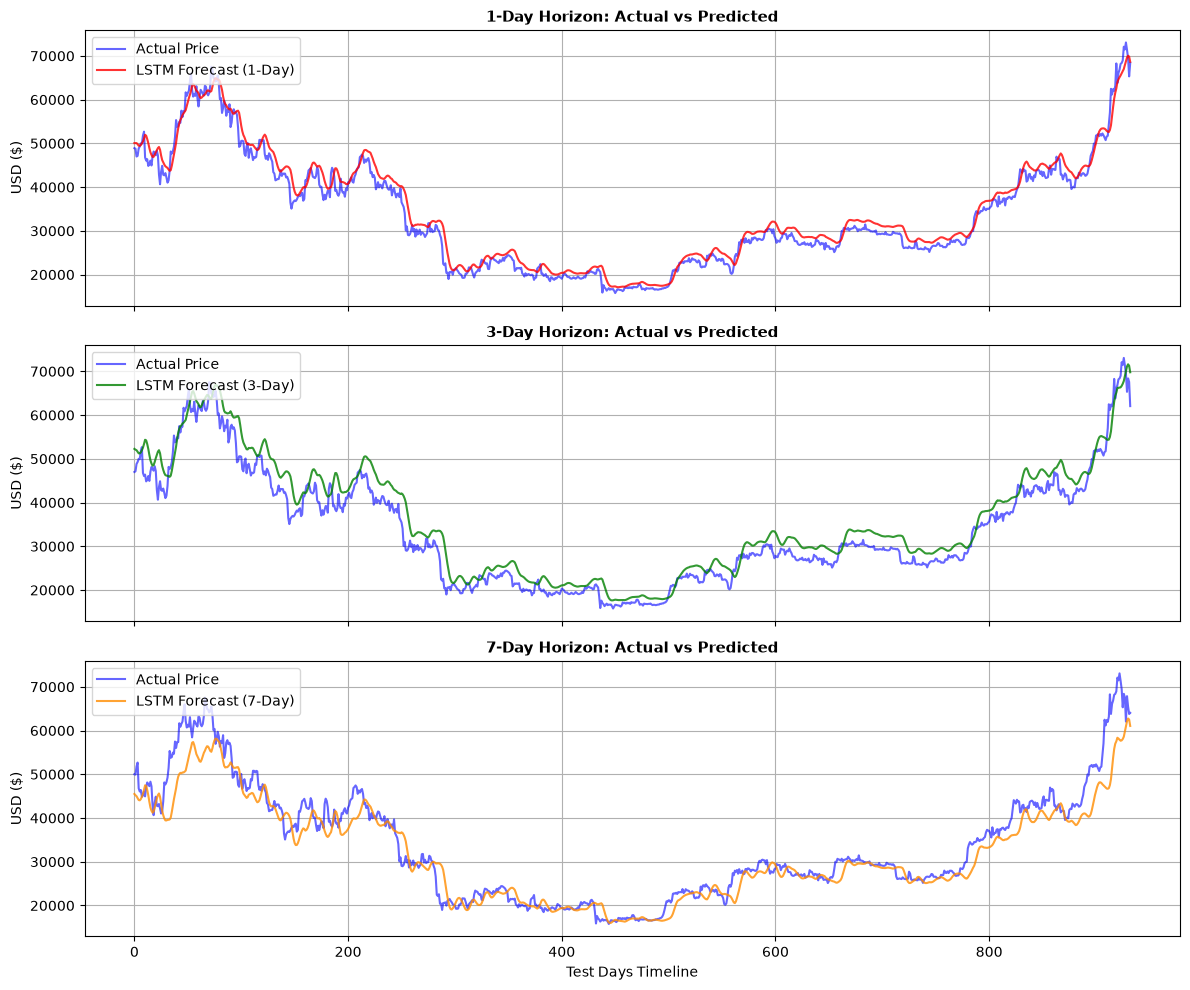

In [25]:
import matplotlib.pyplot as plt

horizons_info = [('1-Day', 1, y_train_1d, y_test_1d, 'red', 0),
                 ('3-Day', 3, y_train_3d, y_test_3d, 'green', 2),
                 ('7-Day', 7, y_train_7d, y_test_7d, 'darkorange', 6)]

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

for i, (name, out_dim, y_tr, y_te, color, idx) in enumerate(horizons_info):
    m = get_model('Stacked LSTM', out_dim)
    m.compile(optimizer='adam', loss='mean_squared_error')
    m.fit(X_train, y_tr, epochs=15, batch_size=32, verbose=0)
    
    preds = scaler.inverse_transform(m.predict(X_test, verbose=0))
    acts = scaler.inverse_transform(y_te.reshape(-1, 1) if out_dim == 1 else y_te)
    
    axes[i].plot(acts if out_dim == 1 else acts[:, idx], label='Actual Price', color='blue', alpha=0.6)
    axes[i].plot(preds if out_dim == 1 else preds[:, idx], label=f'LSTM Forecast ({name})', color=color, alpha=0.8)
    axes[i].set_title(f'{name} Horizon: Actual vs Predicted', fontsize=11, fontweight='bold')
    axes[i].set_ylabel('USD ($)')
    axes[i].legend(loc='upper left')
    axes[i].grid(True)

plt.xlabel('Test Days Timeline')
plt.tight_layout()
plt.show()